# Modularity on the Karate Club Graph
**DSC212 — Graph Theory Module · Research Assignment  **

  Clelia Rose Vadakkethala  

This notebook implements **recursive spectral modularity bisection** from scratch (NumPy + NetworkX only), following Newman (2006), *"Modularity and community structure in networks"*, PNAS 103(23):8577–8582.

**Plan**
1. Load Zachary's Karate Club graph and build $A$, $k$, $B = A - kk^\top/2m$.
2. Verify the theory numerically (symmetry, $B\mathbf 1=0$, Rayleigh–Ritz).
3. Implement the spectral bipartition and recursive splitting using **Newman's generalised modularity matrix** $B^{(C)}$ for every subgroup (stop when $\lambda_1^{(C)}\le 0$, and reject any split that does not increase $Q$).
4. Visualise the graph after every split (fixed layout, one colour per community).
5. After every split compute degree / betweenness / closeness / clustering for every node and plot their evolution.
6. Discussion.

> **Note on metrics.** On the *whole* graph these four quantities never change, so "metrics after each split" only makes sense if they are measured **inside each node's current community** (on the subgraph induced by that community). Iteration 0 is the whole graph; iteration $t$ is the state after the $t$-th split. This is the convention used throughout.

**What this code does.** Imports the libraries I need:
* `numpy` – matrices and eigenvalues
* `networkx` – the graph and centrality measures
* `matplotlib` – the plots

The two `set_printoptions` / `rcParams` lines only make numbers and plots look neat.

In [ ]:
import numpy as np                 # matrices, eigenvalues, linear algebra
import networkx as nx              # graph + centrality measures
import matplotlib.pyplot as plt    # plotting
import matplotlib as mpl           # colour maps

np.set_printoptions(precision=4, suppress=True, linewidth=120)   # print numbers with 4 decimals
plt.rcParams.update({"figure.dpi": 110, "axes.grid": False})     # sharper figures, no grid by default

## 1. Data and the modularity matrix

NetworkX's `karate_club_graph()` stores *interaction counts* as an edge attribute `weight`. The assignment (and the original modularity formulation) uses the **unweighted** graph with $n=34$, $m=78$, so I rebuild a clean unweighted graph and keep only the `club` label (ground truth: `Mr. Hi` vs `Officer`).

**What this code does.**
1. Load the Karate Club graph and rebuild it as a plain **unweighted** graph `G` (an edge exists or it doesn't), keeping only the `club` label.
2. `n` = 34 members, `m` = 78 friendships.
3. `A` = adjacency matrix (1 if two members are friends, else 0).
4. `k` = degree of each member (row sums of `A`).
5. `B = A - kkᵀ/2m` = modularity matrix. It shows how much *more* connected two people are than expected by chance.

The printed check: the degrees add up to `2m = 156`, and the real clubs have 17 + 17 members.

In [ ]:
_raw = nx.karate_club_graph()                 # graph from networkx (has edge weights)
G = nx.Graph()                                # my own clean, unweighted graph
G.add_nodes_from((v, {"club": _raw.nodes[v]["club"]}) for v in _raw.nodes)   # keep only the club label
G.add_edges_from(_raw.edges())                # copy the edges without the weight

nodes = sorted(G.nodes())                     # [0, 1, ..., 33]
n, m = G.number_of_nodes(), G.number_of_edges()                # n = 34 nodes, m = 78 edges
A = nx.to_numpy_array(G, nodelist=nodes, weight=None)         # adjacency matrix (0/1)
k = A.sum(axis=1)                                             # degree of each node = row sum of A
B = A - np.outer(k, k) / (2 * m)                              # modularity matrix B = A - k k^T / 2m

print(f"n = {n}, m = {m}, sum(k) = {int(k.sum())} (= 2m = {2*m})")
print("Ground-truth club sizes:", {c: sum(1 for v in G if G.nodes[v]['club']==c) for c in set(nx.get_node_attributes(G,'club').values())})

n = 34, m = 78, sum(k) = 156 (= 2m = 156)
Ground-truth club sizes: {'Officer': 17, 'Mr. Hi': 17}


### Sanity checks of the theory
* Proposition 1: $B$ is real symmetric.
* Proposition 2 / Corollary 1: $B\mathbf 1 = 0$, so the trivial partition has $Q=0$.
* Theorem 2 (Rayleigh–Ritz): $s^\top B s \le \lambda_1$ for every unit vector $s$, with equality at $u_1$.

**What this code does.** Checks that `B` is built correctly:
* `B` is symmetric.
* `B` times a vector of ones is 0, so "everyone in one group" gives `Q = 0`.
* `eigh(B)` gives the eigenvalues; the biggest is `lam1` with eigenvector `u1`.
* 20,000 random vectors never beat `lam1`, while `u1` reaches it exactly (Rayleigh–Ritz).

In [ ]:
print("B symmetric            :", np.allclose(B, B.T))                  # should be True
print("||B @ 1||_inf          :", np.abs(B @ np.ones(n)).max())         # should be ~0
print("Q(trivial partition)   :", (np.ones(n) @ B @ np.ones(n)) / (4*m)) # one big group -> Q = 0

w, U = np.linalg.eigh(B)                  # eigenvalues (ascending) and eigenvectors of B
lam1, u1 = w[-1], U[:, -1]                # the largest eigenvalue and its eigenvector
print("\nTop 5 eigenvalues of B :", w[::-1][:5])
print("Has an eigenvalue ~0   :", np.isclose(w, 0).any())

rng = np.random.default_rng(0)            # random generator with a fixed seed (same result every run)
vals = []
for _ in range(20000):                    # try 20000 random unit vectors
    s = rng.normal(size=n); s /= np.linalg.norm(s)
    vals.append(s @ B @ s)
print(f"\nmax random s'Bs over 20000 unit vectors = {max(vals):.4f}  <=  lambda_1 = {lam1:.4f}")
print(f"u1' B u1 = {u1 @ B @ u1:.4f}")

B symmetric            : True
||B @ 1||_inf          : 8.881784197001252e-16
Q(trivial partition)   : 8.718097469011646e-18

Top 5 eigenvalues of B : [4.9771 3.0428 2.3202 1.4888 1.4594]
Has an eigenvalue ~0   : True

max random s'Bs over 20000 unit vectors = 1.8604  <=  lambda_1 = 4.9771
u1' B u1 = 4.9771


## 2. Spectral bipartition and recursive bisection

`bisect(C)` tries to split a community $C$ (a set of nodes) in two using the leading eigenvector of the modularity matrix **of the subgroup**.

### Newman's correction for a subgroup (formula used)
For the whole graph the modularity matrix is $B_{ij}=A_{ij}-\dfrac{k_ik_j}{2m}$. For a subgroup $C$ we do **not** use the plain block of $B$. We use Newman's generalised modularity matrix (Newman 2006, eq. 6):

$$B^{(C)}_{ij}=B_{ij}-\delta_{ij}\sum_{l\in C}B_{il},\qquad i,j\in C,$$

that is, the block of $B$ indexed by $C$ with each row sum subtracted on the diagonal. In the code this is `M -= np.diag(M.sum(axis=1))`.

**Why this correction is necessary.** Splitting $C$ into two parts changes the total modularity by

$$\Delta Q=\frac1{4m}\,s^\top B^{(C)}s,$$

and this identity holds *only* for the corrected matrix. The plain block ignores the ties that connect nodes of $C$ to the rest of the graph, so $s^\top(\text{plain block})\,s$ over-states the gain, and its leading eigenvalue is typically positive even for a group that has no internal structure left. The correction restores the property $B^{(C)}\mathbf 1=\mathbf 0$ (every row sums to zero, exactly as for the full $B$), so an indivisible group has $\lambda_1=0$ and the rule "stop when $\lambda_1\le 0$" means what it says. Section 6 demonstrates the failure of the plain block on this very graph.

### Procedure
1. Build $B^{(C)}$ as above and take its leading eigenpair with `numpy.linalg.eigh` (real symmetric matrix, so real eigenvalues and orthonormal eigenvectors; eigenvalues come back in ascending order, so the leading pair is the last one).
2. If $\lambda_1^{(C)}\le 0$ (numerically $\le 10^{-10}$), $C$ is **indivisible**: return `None`.
3. Otherwise split by the sign of $u_1$: $s_i=+1$ if $(u_1)_i>0$, else $-1$.
4. **Guard:** if the *thresholded* split has $\Delta Q=\frac1{4m}s^\top B^{(C)}s\le 0$ (or one side is empty), reject it. The eigenvalue test alone does not guarantee that the rounded $\pm1$ vector improves $Q$.

The sign of an eigenvector is arbitrary, so I fix it by making the largest-magnitude entry positive (this only decides which child is called "+"; the partition itself is unchanged).

`modularity(partition)` uses the **original** $B$: $Q=\frac1{2m}\sum_C\sum_{i,j\in C}B_{ij}$, which for two groups equals $\frac1{4m}s^\top Bs$ (eq. 1 of the handout). It is used to audit every split.

Colour bookkeeping: when community `cid` is split, the $+$ side keeps `cid` and the $-$ side gets a brand-new id, so colours stay comparable between iterations.


**What this code does.** This is the main algorithm, written as small functions:
* `modularity(labels)` – gives `Q` for a division of the nodes; higher is better.
* `leading_eigpair(M)` – biggest eigenvalue and its eigenvector (sign fixed so it is always the same).
* `subgroup_matrix(C)` – takes the part of `B` for community `C` and applies Newman's correction (subtract row sums on the diagonal).
* `bisect(C)` – tries to split one community: if `lam <= 0`, stop. Otherwise positive entries of the eigenvector go to one side, the rest to the other. If the split doesn't raise `Q` (`dQ <= 0`), reject it.
* `recursive_bisection()` – starts with everyone together and keeps splitting until nothing more can be split. Every split is saved in `history`.

The `assert` confirms `Q(after) - Q(before) = dQ`, and the table shows each split and why each final community stopped.

In [ ]:
TOL = 1e-10

def modularity(labels):
    # Q = 1/(2m) * sum_{i,j in same community} B_ij, using the ORIGINAL global B
    labels = np.asarray(labels)
    same = labels[:, None] == labels[None, :]
    return (B * same).sum() / (2 * m)

def leading_eigpair(M):
    vals, vecs = np.linalg.eigh(M)       # ascending eigenvalues, orthonormal eigenvectors
    u = vecs[:, -1].copy()
    u *= np.sign(u[np.argmax(np.abs(u))])  # fix the arbitrary sign: largest-magnitude entry > 0
    return vals[-1], u

def subgroup_matrix(C, generalized=True):
    # B^(C). generalized=True is Newman's eq.(6): subtract each row sum on the diagonal.
    M = B[np.ix_(C, C)].copy()
    if generalized:
        M -= np.diag(M.sum(axis=1))
    return M

def bisect(C, generalized=True, guard=True):
    # Try to split node list C.  Returns (lambda1, C_plus, C_minus, dQ); C_plus is None if C is indivisible.
    C = list(C)
    M = subgroup_matrix(C, generalized)
    lam, u = leading_eigpair(M)
    if lam <= TOL:                                    # indivisible: stop rule  lambda_1 <= 0
        return lam, None, None, None
    s = np.where(u > 0, 1.0, -1.0)
    plus  = [C[i] for i in range(len(C)) if s[i] > 0]
    minus = [C[i] for i in range(len(C)) if s[i] < 0]
    if not plus or not minus:                         # one side empty: cannot split
        return lam, None, None, None
    dQ = s @ M @ s / (4 * m)                          # exact change of Q (only for the corrected matrix)
    if guard and dQ <= TOL:                           # guard: thresholded split must improve Q
        return lam, None, None, dQ
    return lam, plus, minus, dQ

def recursive_bisection(generalized=True, guard=True):
    labels = np.zeros(n, dtype=int)                   # community id of every node
    history = [dict(it=0, labels=labels.copy(), lam=None, dQ=None, split=None, Q=modularity(labels))]
    queue, final_tests, next_id, it = [(0, list(range(n)))], [], 1, 0
    while queue:
        cid, C = queue.pop(0)
        lam, plus, minus, dQ = bisect(C, generalized, guard)
        if plus is None:
            final_tests.append((cid, C, lam, dQ))     # indivisible community
            continue
        it += 1
        labels = labels.copy()
        labels[minus] = next_id                       # '-' side gets a new colour
        history.append(dict(it=it, labels=labels, lam=lam, dQ=dQ, split=(cid, next_id), Q=modularity(labels)))
        queue += [(cid, plus), (next_id, minus)]
        next_id += 1
    return history, final_tests

history, final_tests = recursive_bisection()          # Newman-corrected B^(C) + guard (the method used below)

print(f"{'iter':>4} {'split':>10} {'lambda1':>9} {'dQ':>8} {'#comm':>6} {'Q':>8}")
for h in history:
    sp  = "-" if h['split'] is None else f"{h['split'][0]} -> {h['split'][0]},{h['split'][1]}"
    lam = "-" if h['lam'] is None else f"{h['lam']:.4f}"
    dq  = "-" if h['dQ']  is None else f"{h['dQ']:.4f}"
    print(f"{h['it']:>4} {sp:>10} {lam:>9} {dq:>8} {len(set(h['labels'])):>6} {h['Q']:>8.4f}")
# the dQ column must reproduce the change in Q (this identity holds only for the corrected matrix)
assert all(abs(history[i]['Q'] - history[i-1]['Q'] - history[i]['dQ']) < 1e-9 for i in range(1, len(history)))

print("\nFinal communities (and what stopped them):")
for cid, C, lam, dQ in sorted(final_tests, key=lambda t: t[0]):
    why = "lambda1 <= 0" if lam <= TOL else f"lambda1 > 0 but thresholded split has dQ = {dQ:.4f} <= 0 (guard)"
    print(f"  community {cid}: size {len(C):>2}, lambda1 = {lam:8.4f}, {why}\n      nodes = {sorted(C)}")

iter      split   lambda1       dQ  #comm        Q
   0          -         -        -      1  -0.0000
   1   0 -> 0,1    4.9771   0.3715      2   0.3715
   2   0 -> 0,2    1.1785   0.0012      3   0.3727
   3   1 -> 1,3    0.8594   0.0207      4   0.3934

Final communities (and what stopped them):
  community 0: size  9, lambda1 =   0.0602, lambda1 > 0 but thresholded split has dQ = -0.0158 <= 0 (guard)
      nodes = [1, 2, 3, 7, 12, 13, 17, 19, 21]
  community 1: size  6, lambda1 =   0.0000, lambda1 <= 0
      nodes = [23, 24, 25, 27, 28, 31]
  community 2: size  7, lambda1 =  -0.0000, lambda1 <= 0
      nodes = [0, 4, 5, 6, 10, 11, 16]
  community 3: size 12, lambda1 =  -0.0000, lambda1 <= 0
      nodes = [8, 9, 14, 15, 18, 20, 22, 26, 29, 30, 32, 33]


## 3. Visualisation after each split
A single **fixed** spring layout (seeded) is used for every iteration, nodes are labelled by ID, and each community has its own colour.

**What this code does.** Draws the graph after every split.
* `spring_layout(seed=42)` fixes the node positions, so only the colours change between pictures.
* `draw_partition(h)` draws one step: nodes coloured by community, node numbers inside, title with iteration, number of communities and `Q`.
* The loop draws iteration 0 (all one colour) and then each split.

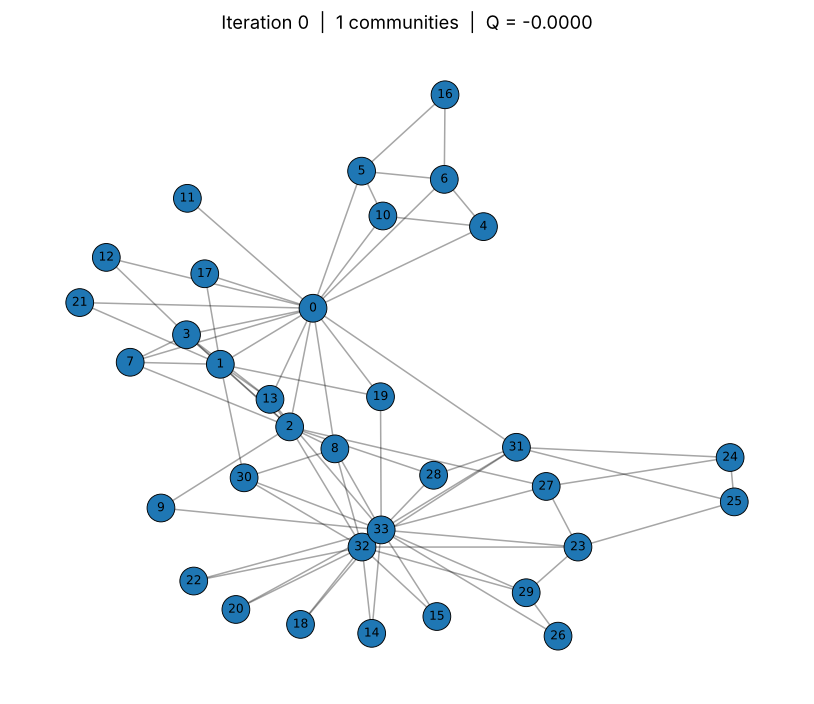

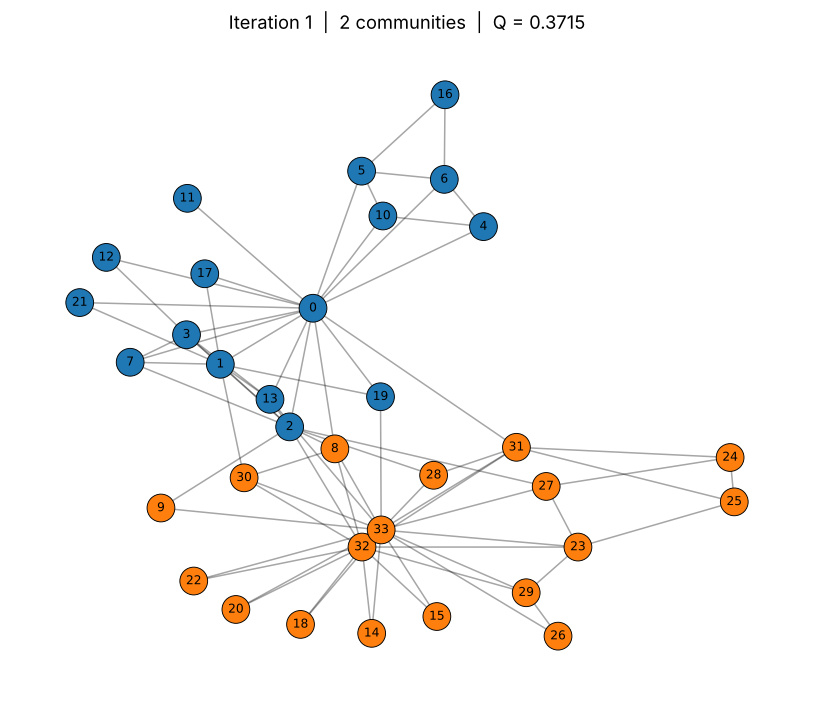

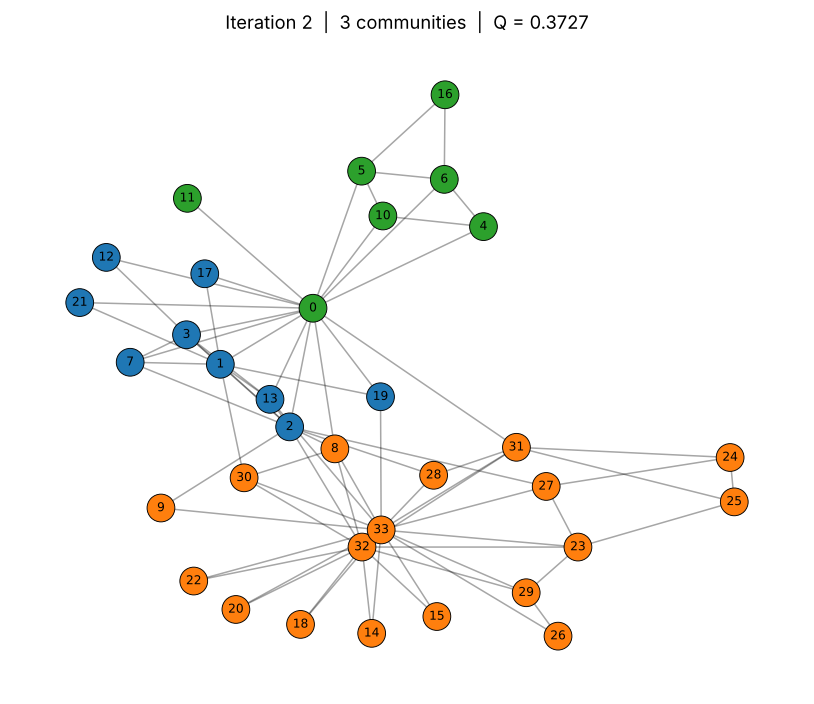

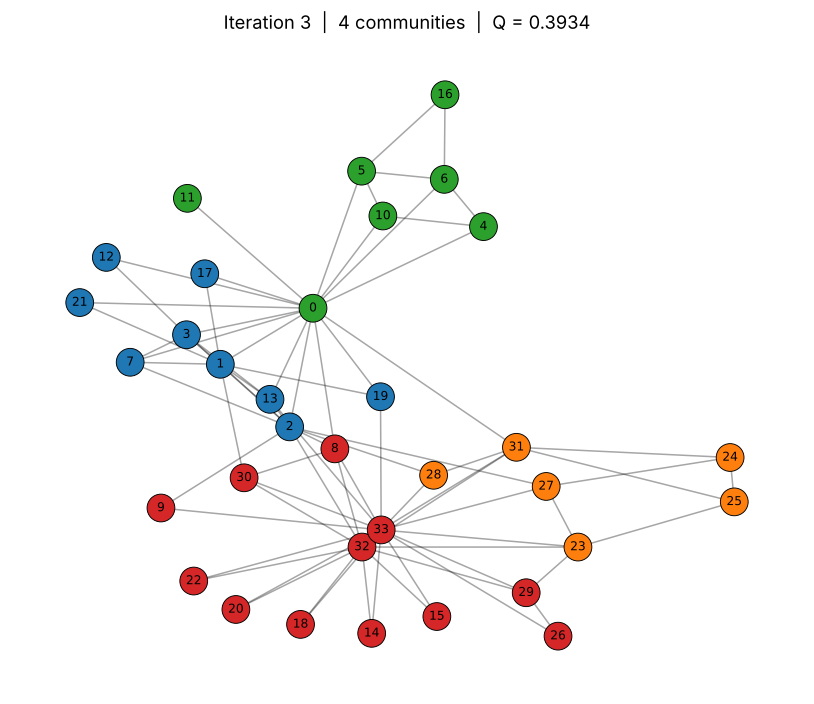

In [ ]:
pos = nx.spring_layout(G, seed=42, k=0.6, iterations=200)   # fixed positions for every drawing
palette = list(mpl.colormaps["tab10"].colors)               # 10 distinct colours

def draw_partition(h, title=None, ax=None):
    labels = h["labels"]                                    # community id of every node at this step
    own = ax is None
    if own: fig, ax = plt.subplots(figsize=(7.5, 6.5))
    colors = [palette[labels[v] % 10] for v in nodes]       # one colour per community
    nx.draw_networkx_edges(G, pos, ax=ax, alpha=0.35, width=1)
    nx.draw_networkx_nodes(G, pos, ax=ax, node_color=colors, node_size=330, edgecolors="k", linewidths=0.6)
    nx.draw_networkx_labels(G, pos, ax=ax, font_size=8)     # write the node number inside each circle
    ax.set_title(title or f"Iteration {h['it']}  |  {len(set(labels))} communities  |  Q = {h['Q']:.4f}")
    ax.set_axis_off()
    if own: plt.tight_layout(); plt.show()

for h in history:                                           # one picture per iteration
    draw_partition(h)

## 4. Node metrics after each split
For iteration $t$ every node's metric is computed with the NetworkX built-ins on the **subgraph induced by its community**:
`degree_centrality`, `betweenness_centrality`, `closeness_centrality`, `clustering`. Results are stored in dictionaries keyed by iteration number.

**What this code does.** Computes degree, betweenness, closeness and clustering for every node after each split. Each is measured **inside the node's own community**.
* `community_metrics(labels)` builds a small graph for each community and calls the networkx functions. A single-node community gets 0.
* `metrics[name][iteration][node]` stores the results.
* The `assert` lines check that iteration 0 equals the whole-graph values.
* The tables (rows = nodes, columns = iterations) are printed. Column 0 is the whole graph.

In [ ]:
def community_metrics(labels):
    out = {name: {} for name in ("degree", "betweenness", "closeness", "clustering")}
    for c in sorted(set(labels)):                              # go through each community
        members = [v for v in nodes if labels[v] == c]
        H = G.subgraph(members)                                # graph of this community only
        if len(members) == 1:                                  # single node: all metrics are 0
            for name in out: out[name][members[0]] = 0.0
            continue
        for name, f in (("degree", nx.degree_centrality), ("betweenness", nx.betweenness_centrality),
                        ("closeness", nx.closeness_centrality), ("clustering", nx.clustering)):
            out[name].update(f(H))                             # compute the metric on H
    return out

metrics = {name: {} for name in ("degree", "betweenness", "closeness", "clustering")}   # metrics[name][iteration][node]
for h in history:                                              # repeat for every iteration
    res = community_metrics(h["labels"])
    for name in metrics:
        metrics[name][h["it"]] = res[name]

# check: iteration 0 must equal the values on the whole graph
assert all(abs(metrics["degree"][0][v] - nx.degree_centrality(G)[v]) < 1e-12 for v in nodes)
assert all(abs(metrics["clustering"][0][v] - nx.clustering(G)[v]) < 1e-12 for v in nodes)

import pandas as pd
its = [h["it"] for h in history]                               # [0, 1, 2, 3]
tables = {name: pd.DataFrame({it: metrics[name][it] for it in its}).round(3) for name in metrics}

# print the full table (all 34 nodes) of every metric
titles_print = {"degree": "Degree centrality", "closeness": "Closeness centrality",
                "clustering": "Clustering coefficient", "betweenness": "Betweenness centrality"}
for name in ("degree", "closeness", "clustering", "betweenness"):
    print(f"--- {titles_print[name]} (rows = node, columns = iteration) ---")
    print(tables[name].to_string(), "\n")

--- Degree centrality (rows = node, columns = iteration) ---
        0      1      2      3
0   0.485  0.933  0.833  0.833
1   0.273  0.533  0.875  0.875
2   0.303  0.333  0.500  0.500
3   0.182  0.400  0.625  0.625
4   0.091  0.200  0.500  0.500
5   0.121  0.267  0.667  0.667
6   0.121  0.267  0.667  0.667
7   0.121  0.267  0.375  0.375
8   0.152  0.176  0.176  0.273
9   0.061  0.059  0.059  0.091
10  0.091  0.200  0.500  0.500
11  0.030  0.067  0.167  0.167
12  0.061  0.133  0.125  0.125
13  0.152  0.267  0.375  0.375
14  0.061  0.118  0.118  0.182
15  0.061  0.118  0.118  0.182
16  0.061  0.133  0.333  0.333
17  0.061  0.133  0.125  0.125
18  0.061  0.118  0.118  0.182
19  0.091  0.133  0.125  0.125
20  0.061  0.118  0.118  0.182
21  0.061  0.133  0.125  0.125
22  0.061  0.118  0.118  0.182
23  0.152  0.294  0.294  0.400
24  0.091  0.176  0.176  0.600
25  0.091  0.176  0.176  0.600
26  0.061  0.118  0.118  0.182
27  0.121  0.176  0.176  0.400
28  0.091  0.118  0.118  0.200
29  0.121

## 5. Evolution of the metrics
Left: line plot per node across iterations (the 5 nodes with the largest **final** value and the two faction leaders, nodes 0 = Mr. Hi and 33 = the Officer, are highlighted; all others are grey). Right: heat-map of all 34 nodes × iterations.

**What this code does.** For each metric, draws two plots:
* **Left:** a line per node across the iterations. Only the top 5 nodes at the end plus the leaders 0 and 33 are coloured; the rest are grey.
* **Right:** a heat-map of all 34 nodes over the iterations (bright = high).

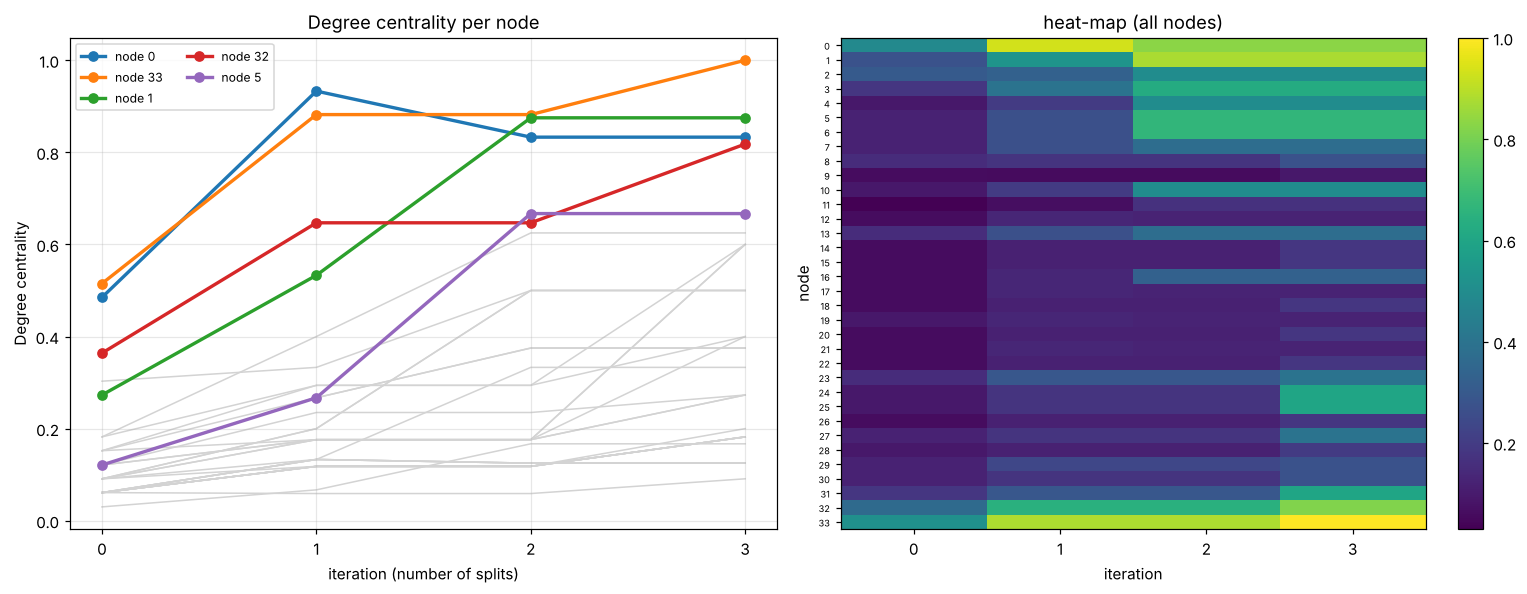

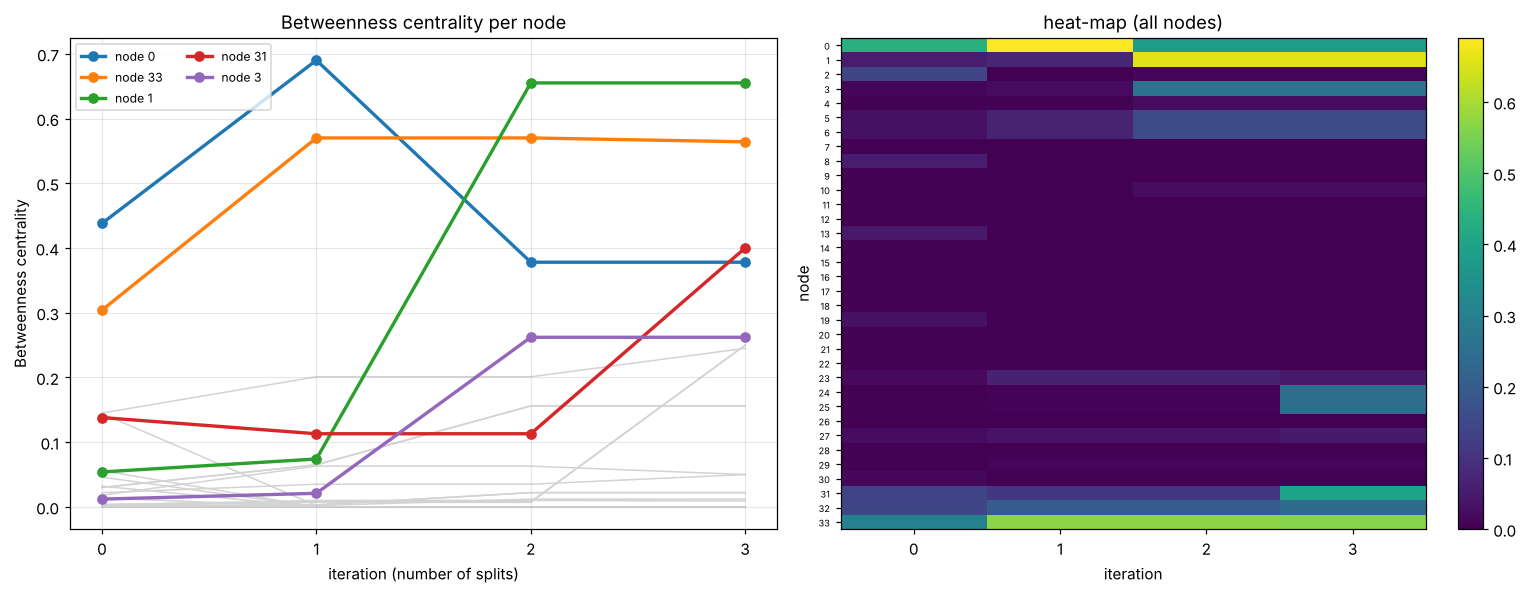

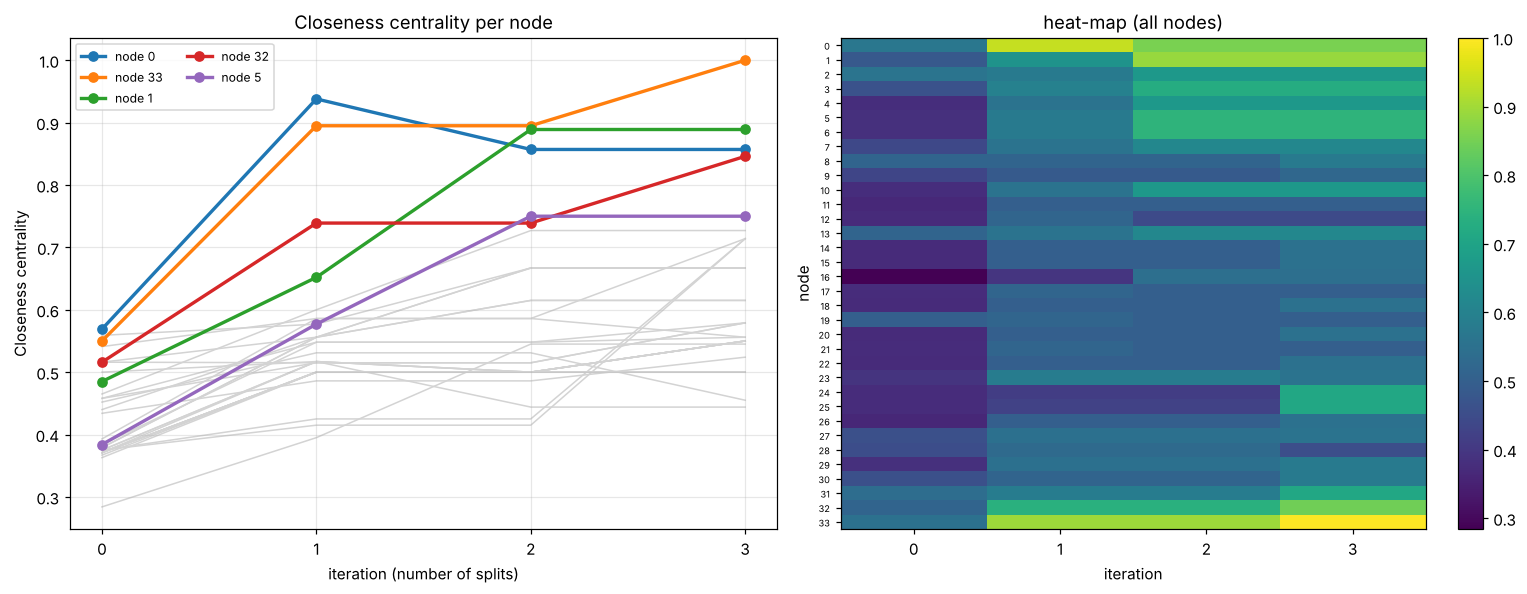

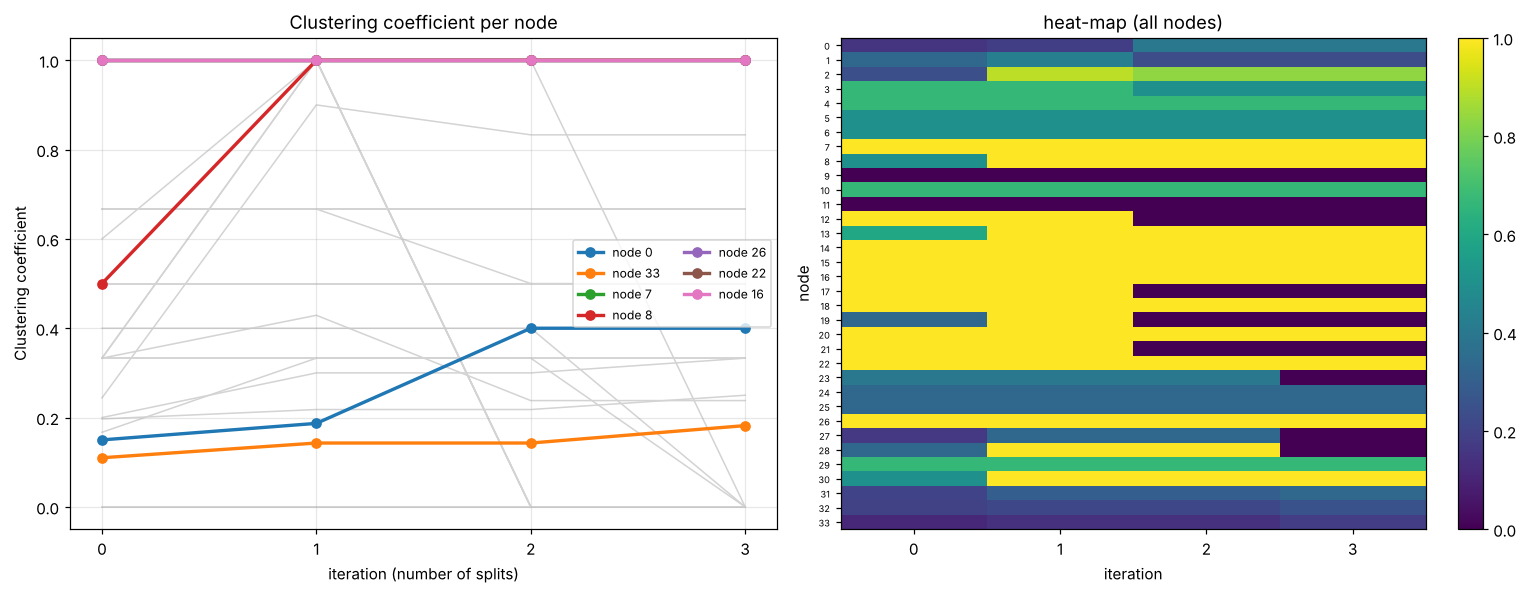

In [ ]:
titles = {"degree": "Degree centrality", "betweenness": "Betweenness centrality",
          "closeness": "Closeness centrality", "clustering": "Clustering coefficient"}
last = its[-1]                                  # last iteration number

for name in metrics:                              # one figure per metric
    T = tables[name]                              # table: rows = nodes, columns = iterations
    # the 5 nodes with the highest value at the end, plus the leaders 0 and 33, get colours
    top = list(T[last].sort_values(ascending=False).index[:5])
    hi = list(dict.fromkeys([0, 33] + top))
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(14, 5.5), gridspec_kw={"width_ratios": [1.1, 1]})
    for v in nodes:
        if v not in hi: a1.plot(its, T.loc[v], color="lightgrey", lw=1, zorder=1)
    cmap = mpl.colormaps["tab10"]
    for j, v in enumerate(hi):
        a1.plot(its, T.loc[v], marker="o", lw=2.2, color=cmap(j % 10), label=f"node {v}", zorder=3)
    a1.set_xticks(its); a1.set_xlabel("iteration (number of splits)"); a1.set_ylabel(titles[name])
    a1.set_title(f"{titles[name]} per node"); a1.legend(ncol=2, fontsize=8); a1.grid(alpha=.3)
    # right plot: heat-map of all nodes
    im = a2.imshow(T.values, aspect="auto", cmap="viridis")
    a2.set_xticks(range(len(its))); a2.set_xticklabels(its)
    a2.set_yticks(range(n)); a2.set_yticklabels(T.index, fontsize=6)
    a2.set_xlabel("iteration"); a2.set_ylabel("node"); a2.set_title("heat-map (all nodes)")
    plt.colorbar(im, ax=a2, fraction=0.04)
    plt.tight_layout(); plt.show()

**What this code does.** Finds which nodes stay important throughout.
1. Rank the nodes on each metric at every iteration (1 = highest).
2. Average the ranks over the iterations, then over the four metrics. **Smaller = more consistently central.**
3. Print the best 8 nodes, and the top 3 of every metric at every iteration.

In [ ]:
# How consistently does each node stay central?  Rank (1 = most central) at every iteration.
ranks = {name: tables[name].rank(ascending=False, method="min") for name in metrics}
# mean rank of every node for each of the four metrics
summary = pd.DataFrame({
    f"{name[:5]} mean rank": ranks[name].mean(axis=1) for name in metrics
})
# average of the four mean ranks (small = consistently central)
summary["avg of mean ranks"] = summary.mean(axis=1)
summary = summary.sort_values("avg of mean ranks").round(2)
print("Nodes ranked by average rank over all iterations and all four metrics (lower = more consistently central):")
print(summary.head(8).to_string())

print("\nTop-3 nodes per metric at each iteration:")
for name in metrics:
    print(f"\n{titles[name]}")
    for it in its:
        s = tables[name][it].sort_values(ascending=False)
        print(f"  it {it}: " + ", ".join(f"{v} ({val:.3f})" for v, val in s.head(3).items()))

Nodes ranked by average rank over all iterations and all four metrics (lower = more consistently central):
    degre mean rank  betwe mean rank  close mean rank  clust mean rank  avg of mean ranks
0              2.25             2.25             2.00            25.25               7.94
33             1.25             2.00             1.75            29.25               8.56
1              3.25             3.50             4.25            24.00               8.75
3              6.25             8.50             7.25            15.75               9.44
32             4.00             4.75             4.50            27.25              10.12
13            11.00            14.75            10.25             4.75              10.19
6              7.25             7.75             8.50            18.00              10.38
5              7.25             7.75             8.50            18.00              10.38

Top-3 nodes per metric at each iteration:

Degree centrality
  it 0: 33 (0.515), 0

## 6. Validation against ground truth and why the correction matters
Zachary recorded the actual split (`Mr. Hi` vs `Officer`). The **first** spectral split should reproduce it (for the whole graph $B^{(C)}=B$, so the correction changes nothing there).

I then rerun the recursion with the **plain block** of $B$ (no correction, no guard) to show what goes wrong without Newman's eq. 6: the plain block's $\lambda_1$ stays positive for groups that cannot be improved, its eigenvector is often one-signed, and $s^\top B_{\text{block}}\,s/4m$ no longer equals the true change in $Q$.


**What this code does.**
1. Compares my first split with the real club split (`truth`) and counts the mismatched nodes.
2. Reruns the algorithm with the plain `B` block (no correction, no guard) to see what goes wrong.
3. Prints `Q` after each iteration for both methods, and their final communities.
4. Shows the plain method's communities that still have `lambda1 > 0` even though they can't be split.
5. Prints networkx's greedy modularity result as a reference only.

In [ ]:
first = history[1]["labels"]
truth = np.array([0 if G.nodes[v]["club"] == "Mr. Hi" else 1 for v in nodes])
mis_a = np.where(first != truth)[0]; mis_b = np.where(first == truth)[0]
mis = [int(v) for v in (mis_a if len(mis_a) <= len(mis_b) else mis_b)]    # label names are arbitrary -> take the smaller mismatch
print(f"First split vs. the real club split: {n-len(mis)}/{n} nodes correct ({(n-len(mis))/n:.1%}); misclassified node(s): {mis}")
print("Split sizes:", np.bincount(first), "| truth sizes:", np.bincount(truth))

hist_p, final_p = recursive_bisection(generalized=False, guard=False)    # plain block, no guard (what the correction replaces)
print("\nQ along the recursion")
print(f"{'iter':>4} {'plain block':>13} {'Newman B^(C) + guard':>22}")
for i in range(max(len(history), len(hist_p))):
    a = f"{hist_p[i]['Q']:.4f}" if i < len(hist_p) else "-"
    b = f"{history[i]['Q']:.4f}" if i < len(history) else "-"
    print(f"{i:>4} {a:>13} {b:>22}")
print("\nFinal communities, Newman corrected :", sorted(sorted(C) for _, C, _, _ in final_tests))
print("Final communities, plain block      :", sorted(sorted(C) for _, C, _, _ in final_p))

print("\nPlain block: communities that still have lambda1 > 0 although they cannot be split into two sign groups")
for cid, C, lam, dQ in sorted(final_p, key=lambda t: t[0]):
    if lam > TOL:
        print(f"  size {len(C):>2}, lambda1 = {lam:.4f}  nodes = {sorted(C)}")
iso = [C for _, C, _, _ in final_p if len(C) == 1]
if iso:
    v = iso[0][0]
    print(f"\nNote: the plain block of the single node {v} is [[{B[v, v]:.4f}]]; the corrected 1x1 block is exactly 0 (row sum subtracted).")

# reference: NetworkX's own greedy optimiser (for comparison only, not used in the algorithm)
ref = nx.community.greedy_modularity_communities(G)
print(f"\nReference (greedy modularity, networkx): {len(ref)} communities, Q = {nx.community.modularity(G, ref):.4f}")

First split vs. the real club split: 33/34 nodes correct (97.1%); misclassified node(s): [8]
Split sizes: [16 18] | truth sizes: [17 17]

Q along the recursion
iter   plain block   Newman B^(C) + guard
   0       -0.0000                -0.0000
   1        0.3715                 0.3715
   2        0.3898                 0.3727
   3        0.4081                 0.3934
   4        0.4094                      -

Final communities, Newman corrected : [[0, 4, 5, 6, 10, 11, 16], [1, 2, 3, 7, 12, 13, 17, 19, 21], [8, 9, 14, 15, 18, 20, 22, 26, 29, 30, 32, 33], [23, 24, 25, 27, 28, 31]]
Final communities, plain block      : [[0, 1, 2, 3, 7, 12, 13, 17, 19, 21], [4, 5, 6, 10, 16], [8, 9, 14, 15, 18, 20, 22, 23, 26, 29, 30, 32, 33], [11], [24, 25, 27, 28, 31]]

Plain block: communities that still have lambda1 > 0 although they cannot be split into two sign groups
  size 10, lambda1 = 2.5712  nodes = [0, 1, 2, 3, 7, 12, 13, 17, 19, 21]
  size 13, lambda1 = 2.3563  nodes = [8, 9, 14, 15, 18, 20, 2

## 7. Discussion

---

### 7.1 What I did and what I learned

I started with the main idea of modularity. A network has good community structure when there are many connections inside the communities and very few connections between them. That is high modularity. When the connections are spread everywhere with no groups, that is low modularity.

To measure this, I compare the real graph with a random graph that has the same degrees and ask how many edges we would expect inside a group by chance. This is why the modularity matrix is $B = A - \dfrac{kk^\top}{2m}$: the second term is the chance part. For a split into two groups, with $s_i = \pm 1$, the modularity is $Q = \dfrac{1}{4m}\, s^\top B s$. The question "what is the best split?" therefore becomes "which $s$ gives the largest $s^\top B s$?".

#### Understanding the algorithm

This was the part I had to go slowly on.

**The spectral shortcut.** Checking every possible $s$ is too much for 34 members, so the spectral method uses eigenvalues instead:

* **Relaxation:** $s$ must be $\pm 1$, which is hard to optimise, so I allow any real unit vector.
* **Rayleigh–Ritz:** the maximum of $s^\top B s$ is the largest eigenvalue $\lambda_1$, reached at its eigenvector $u_1$. I checked this numerically: none of 20,000 random unit vectors beat $\lambda_1 = 4.98$.
* **Thresholding:** positive entries of $u_1$ go to one group and the rest to the other, which brings $s$ back to $\pm 1$.
* **Recursive bisection:** the same steps are repeated on each new group, which gives more than two communities.

**The stopping rule.** If $\lambda_1 \le 0$, the group cannot be split to improve $Q$, so I stop. But $\lambda_1 > 0$ only says that a real-valued vector could improve $Q$. After thresholding, $Q$ can still go down, so I also check $\Delta Q$.

---

### 7.2 Results

Recursive spectral bisection with Newman's generalised matrix $B^{(C)}$ ends with **4 communities** and $Q = 0.393$. For comparison, greedy modularity in NetworkX finds 3 communities with $Q = 0.381$, and the best known value for this graph is about $0.42$.

The very first split ($\lambda_1 = 4.98$, $Q = 0.372$) already recovers Zachary's real fission and puts 33 of 34 members on the correct side. Only node 8 is misplaced, and he is also the member who is famously ambiguous in the original study. The later splits raise $Q$ from $0.372 \to 0.373 \to 0.393$. Each gain equals $\Delta Q = \dfrac{1}{4m}\, s^\top B^{(C)} s$, which the code asserts.

**Stopping.** The final communities are:

* $\{0, 4, 5, 6, 10, 11, 16\}$
* $\{1, 2, 3, 7, 12, 13, 17, 19, 21\}$
* $\{8, 9, 14, 15, 18, 20, 22, 26, 29, 30, 32, 33\}$
* $\{23, 24, 25, 27, 28, 31\}$

Three of the four final communities stop because $\lambda_1^{(C)} \le 0$, as the theory says. The fourth (9 nodes, $\lambda_1 = 0.060$) has a small positive eigenvalue, but its thresholded split would lower $Q$ ($\Delta Q = -0.016$), so the guard rejects it. This shows why the guard is needed.

---

### 7.3 My mistake and the correction

My first run used the plain block of $B$ for each subgroup. It gave 5 communities, and the 5th was a single node (node 11). Its $Q = 0.409$ was higher, so at first it looked better, but it felt wrong that one person alone formed a community. When I checked, I found that four groups still had a positive $\lambda_1$ even though they could not be split, and the gain from the formula did not match the real change in $Q$. For example, $\lambda_1 = 2.57$ for a 10-node group, with a one-signed eigenvector.

The reason is that the small block of $B$ ignores the friendships that go outside the group. Newman's correction subtracts the row sums on the diagonal:

$$B^{(C)}_{ij} = B_{ij} - \delta_{ij} \sum_{l \in C} B_{il}.$$

This restores $B^{(C)}\mathbf{1} = \mathbf{0}$, so an indivisible group has $\lambda_1 = 0$. After applying it, I got 4 communities with $Q = 0.393$. This is a bit lower, but every step now follows the theory: $\Delta Q$ matches the real change, and the rule $\lambda_1 \le 0$ actually works. The higher $Q$ of the plain method is therefore not evidence that it is better. Its recursion ended because no sign split existed, not because the stopping rule fired.

---

### 7.4 Node metrics: who stays central?

The four metrics are described below. On the whole graph these never change, so I measured them inside each node's own community after every split.

| Metric | What it measures |
|:--|:--|
| **Degree** | how many friends a node has |
| **Betweenness** | how often a node lies on shortest paths |
| **Closeness** | how near a node is to all others |
| **Clustering** | how many of its friends are friends with each other |

#### The consistent hubs

Nodes **0 (Mr. Hi)** and **33 (the Officer)** are the consistent hubs.

| Node | Role | Mean rank: degree | Mean rank: betweenness | Mean rank: closeness | Note |
|:--:|:--|:--:|:--:|:--:|:--|
| **0** | Mr. Hi | 2.25 | 2.25 | 2.0 | best mean ranks over all iterations |
| **33** | the Officer | 1.25 | 2.0 | 1.75 | first or second on degree and closeness at every iteration |
| **1** | broker | – | – | – | third most consistent node; top-betweenness node (0.655) from the second split on, once it is the broker of its own community |
| **32** | – | – | – | – | ranks right behind them in the full graph |

This matches the history of the club: the two rival leaders are the centres of their factions.

#### How community structure changes the metrics

| Metric | What happens after a split | Example from the output | Meaning |
|:--|:--|:--|:--|
| **Degree and closeness** | They inflate. They are now normalised by $\lvert C\rvert - 1$ instead of $n - 1$. | Node 0 goes from 0.485 to 0.933 after the first split. Node 33 reaches 1.0 in the last iteration because it is adjacent to every other member of its community. | The hubs sit at the core of a tight group, not that they gained connections; the cross-community edges are simply no longer counted. |
| **Betweenness** | It separates global from local brokers. | Node 0 rises from 0.438 to 0.690 after the first split, then falls to 0.378 when the group $\{4, 5, 6, 10, 16\}$, which reached the rest of Mr. Hi's side through node 0, is separated from it. | Values from small communities are a local statement and should not be compared with whole-graph values. |
| **Clustering** | It identifies the periphery. | – | – |

**Clustering coefficient: the tightly knit members.** The clustering coefficient of a node is the fraction of pairs of its friends who are also friends with each other. It is 1 when all of its friends know each other, and 0 when none do. NetworkX also gives 0 to any node with fewer than 2 friends, since no pair exists.

#### Overall reading of the metrics

| Metrics | What a high value marks | Nodes |
|:--|:--|:--|
| **Degree, closeness, betweenness** | leaders and bridges | 0, 33, 1, 32 |
| **Clustering** | members who are well embedded in a closed local group, but rarely the ones who connect different groups | 7, 8, 14, 15, 16, 18, 20, 22, 26 |

This is why the hubs 0 and 33 average only around 25th–30th on clustering rank, while having the best average ranks on the other three metrics.

---

### Inference: How this helps in the real world

After seeing the graphs and the results, I understood that this assignment is not only about the Karate Club. The same method works for any network where we know who is connected to whom. In my graph, the method found the two real groups just from the friendship links, and the metrics showed me who the leaders and the bridges were. I think the same thing can be done in real life.

1. **Friend suggestions.** If you are in a community with many mutual friends, the people in that community you haven't connected with yet are likely good suggestions. This is the same idea as your Karate Club result: people in the same group have many more links among themselves than chance would give.

2. **Showing relevant content.** Communities usually share interests, such as a college, a hobby or a fan group. A platform can show posts and pages that are popular inside your community.

3. **Finding groups automatically.** A platform can detect groups without anyone labelling them, just from the connection pattern. For example, it can discover that a set of users forms a cricket-fan group even though none of them said so.

4. **Finding influencers and bridges.** The node metrics help here:
   * **High degree** marks the popular people with many connections.
   * **High betweenness** marks people who connect two different communities. They are important for spreading news or ideas from one group to another.
   * **High closeness** marks people who can reach everyone quickly, so a message from them travels fast.

   In your assignment, nodes 0 and 33 were the leaders of their groups, and node 1 was a strong broker in its own community. In a social network, the leaders would be influencers, and the brokers would be the people who carry information between groups.

5. **Spotting fake accounts and spam.** A group of accounts that are tightly linked to each other but have almost no real connections to anyone else looks suspicious. Community detection can help flag it for checking.

6. **Understanding how information spreads.** Information spreads fast inside a community but slowly between communities. This helps explain why a rumour or a trend can stay inside one group, and which people can carry it outside.

---

### Conclusion

This assignment showed how modularity and the spectral method can be used to find communities in a network from its connections alone.
Working through the algorithm step by step, including correcting my own mistake, taught me to check each result carefully instead of accepting it at first sight.
Studying the node metrics showed me that different measures describe different roles of members within a network.
Overall, the assignment gave me a clear understanding of community detection and how it applies to real-world networks.


## References
* M. E. J. Newman (2006). *Modularity and community structure in networks.* PNAS 103(23):8577–8582.
* W. W. Zachary (1977). *An information flow model for conflict and fission in small groups.* Journal of Anthropological Research 33(4):452–473.
* Course handout, *Modularity on the Karate Club Graph*, DSC212: Graph Theory Module.